## Importación de librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

## Sección 1: Preparación y escalado de características para distancias

In [2]:
# 1. Cargar el dataset limpio de la actividad anterior
df = pd.read_csv('healthcare-dataset-stroke-data-limpio.csv')

# Guardar la columna objetivo 'stroke' por separado para la validación final
stroke_real = df['stroke'].copy()

# Eliminar la columna objetivo 'stroke' y el identificador 'id' (si existe en el dataset)
columnas_a_eliminar = [col for col in ['stroke', 'id'] if col in df.columns]
df_sin_etiquetas = df.drop(columns=columnas_a_eliminar)

# 2. Seleccionar las variables numéricas y continuas clave
features = ['age', 'avg_glucose_level', 'bmi']
X = df_sin_etiquetas[features].copy()

# 3. Aplicar StandardScaler para estandarizar (media = 0, desviación estándar = 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convertir a DataFrame para verificar la transformación
X_scaled_df = pd.DataFrame(X_scaled, columns=features)
print("Primeras filas de los datos escalados:")
print(X_scaled_df.head())

Primeras filas de los datos escalados:
        age  avg_glucose_level       bmi
0  1.051434           2.706375  1.005086
1  0.786070           2.121559 -0.098981
2  1.626390          -0.005028  0.472536
3  0.255342           1.437358  0.719327
4  1.582163           1.501184 -0.631531


## Sección 2: Búsqueda del número óptimo de clústeres (método del codo y silueta)

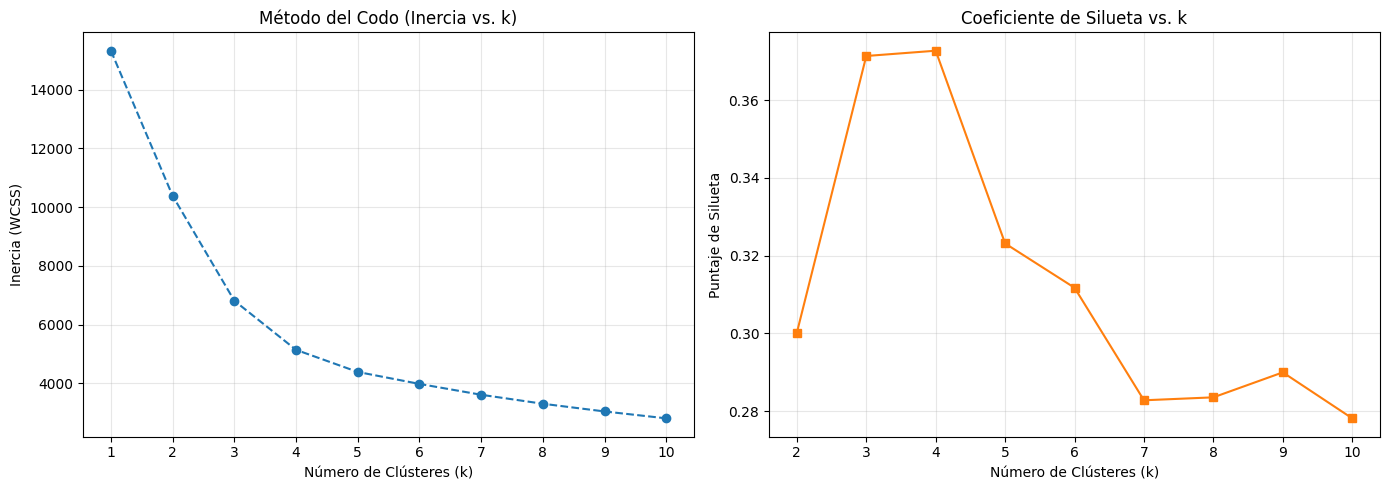

In [3]:
# Listas para almacenar las métricas de evaluación por cada valor de k
inercias = []
siluetas = []
rango_k = range(1, 11)

for k in rango_k:
    # Inicializar y entrenar K-Means con semilla fija para reproducibilidad
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = kmeans.fit_predict(X_scaled)

    # Guardar la inercia (suma de distancias cuadradas intra-clúster)
    inercias.append(kmeans.inertia_)

    # El coeficiente de silueta requiere al menos 2 clústeres para calcularse
    if k > 1:
        score = silhouette_score(X_scaled, etiquetas)
        siluetas.append(score)

# Graficar ambos métodos en una figura comparativa
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Subgráfica 1: Método del Codo
ax[0].plot(rango_k, inercias, marker='o', linestyle='--', color='#1f77b4')
ax[0].set_title('Método del Codo (Inercia vs. k)')
ax[0].set_xlabel('Número de Clústeres (k)')
ax[0].set_ylabel('Inercia (WCSS)')
ax[0].set_xticks(rango_k)
ax[0].grid(True, alpha=0.3)

# Subgráfica 2: Coeficiente de Silueta (k desde 2 hasta 10)
ax[1].plot(range(2, 11), siluetas, marker='s', linestyle='-', color='#ff7f0e')
ax[1].set_title('Coeficiente de Silueta vs. k')
ax[1].set_xlabel('Número de Clústeres (k)')
ax[1].set_ylabel('Puntaje de Silueta')
ax[1].set_xticks(range(2, 11))
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Sección 3: entrenamiento del modelo y visualización de centroides

Coordenadas de los centroides (en unidades originales):
         age  avg_glucose_level        bmi
0  60.027748          89.535139  27.741622
1  41.524838          90.321836  39.025702
2  17.888347          92.672788  22.807566
3  60.543964         207.298152  32.753800


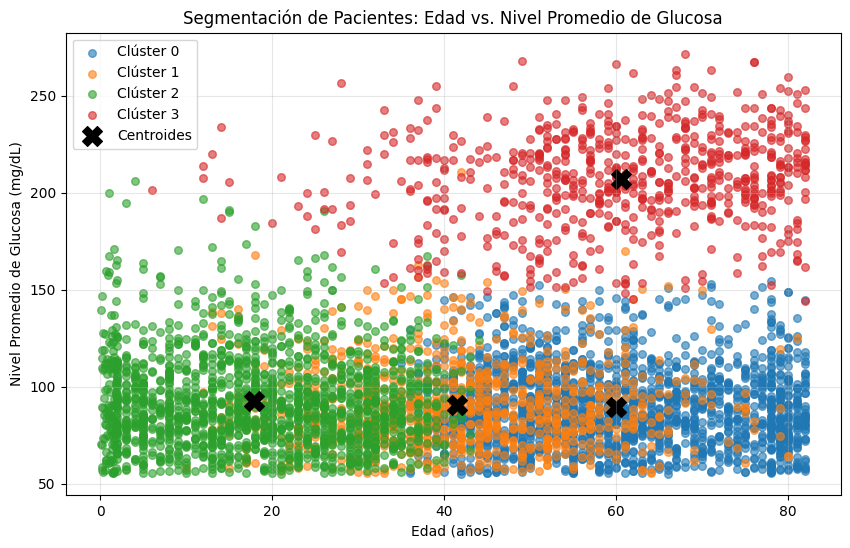

In [4]:
# 1. Definir el valor óptimo de k y entrenar el modelo final
k_optimo = 4
modelo_final = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
clusters_asignados = modelo_final.fit_predict(X_scaled)

# Añadir la etiqueta de clúster al DataFrame original de características
X['Cluster'] = clusters_asignados

# 2. Obtener las coordenadas de los centroides (en escala normalizada y en escala original)
centroides_escalados = modelo_final.cluster_centers_
centroides_originales = scaler.inverse_transform(centroides_escalados)

df_centroides = pd.DataFrame(centroides_originales, columns=features)
print("Coordenadas de los centroides (en unidades originales):")
print(df_centroides)

# 3. Gráfico de dispersión: Edad (índice 0) vs. Nivel de Glucosa (índice 1)
plt.figure(figsize=(10, 6))

for c in range(k_optimo):
    subset = X[X['Cluster'] == c]
    plt.scatter(
        subset['age'],
        subset['avg_glucose_level'],
        label=f'Clúster {c}',
        alpha=0.6,
        s=30
    )

# Graficar los centroides con una 'X' grande
plt.scatter(
    centroides_originales[:, 0],
    centroides_originales[:, 1],
    c='black',
    marker='X',
    s=200,
    label='Centroides'
)

plt.title('Segmentación de Pacientes: Edad vs. Nivel Promedio de Glucosa')
plt.xlabel('Edad (años)')
plt.ylabel('Nivel Promedio de Glucosa (mg/dL)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Sección 4: Validación cruzada

Conteo absoluto de casos por Clúster:
stroke      0    1
Cluster           
0        1736  141
1         907   15
2        1635    4
3         583   89

Porcentaje de casos de derrame cerebral (stroke = 1) por Clúster:
stroke       0      1
Cluster              
0        92.49   7.51
1        98.37   1.63
2        99.76   0.24
3        86.76  13.24


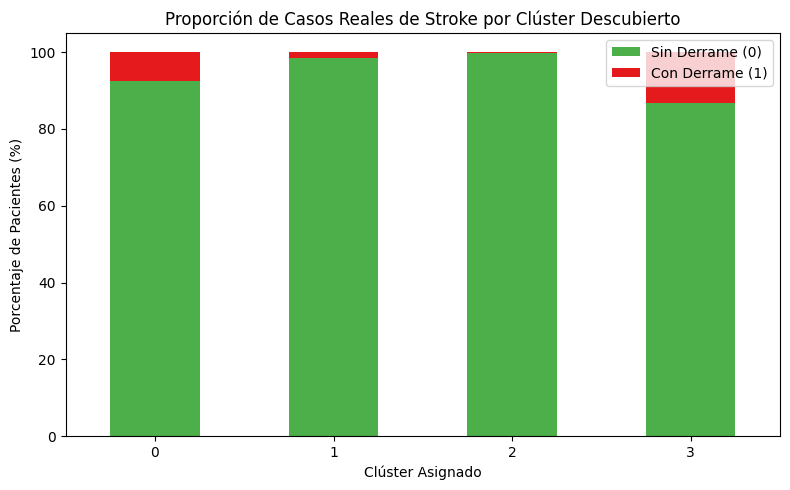

In [5]:
# 1. Reincorporar la columna objetivo 'stroke' guardada
X['stroke'] = stroke_real.values

# 2. Crear tabla cruzada de conteos absolutos y proporciones porcentuales por fila
tabla_conteos = pd.crosstab(X['Cluster'], X['stroke'])
tabla_proporciones = pd.crosstab(X['Cluster'], X['stroke'], normalize='index') * 100

print("Conteo absoluto de casos por Clúster:")
print(tabla_conteos)
print("\nPorcentaje de casos de derrame cerebral (stroke = 1) por Clúster:")
print(tabla_proporciones.round(2))

# Gráfico de barras apiladas para visualizar la proporción de riesgo por clúster
tabla_proporciones.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5),
    color=['#4daf4a', '#e41a1c']
)
plt.title('Proporción de Casos Reales de Stroke por Clúster Descubierto')
plt.xlabel('Clúster Asignado')
plt.ylabel('Porcentaje de Pacientes (%)')
plt.xticks(rotation=0)
plt.legend(['Sin Derrame (0)', 'Con Derrame (1)'], loc='upper right')
plt.tight_layout()
plt.show()